# Page Blocks Classification

Document-image understanding, 1990s style: a page-segmentation algorithm has already cut scanned pages into rectangular **blocks**. Each block is described by 10 geometric and density measurements (height, length, area, eccentricity, proportion of black pixels, transitions…). The job is to label each block as **text (1), horizontal line (2), picture (3), vertical line (4) or graphic (5)** — the first step of turning a scanned page back into a structured document.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# UCI serves this dataset as a ready CSV at the dataset's data_url (Page Blocks is id 78 in the current UCI repository)
df = pd.read_csv(io.BytesIO(download('https://archive.ics.uci.edu/static/public/78/data.csv')))
print(df.shape)
print(df['class'].value_counts().sort_index())
df.head(3)

(5473, 11)
class
1    4913
2     329
3      28
4      88
5     115
Name: count, dtype: int64


,height,length,area,eccen,p_black,p_and,mean_tr,blackpix,blackand,wb_trans,class
0,5,7,35,1.400,0.400,0.657,2.33,14,23,6,1
1,6,7,42,1.167,0.429,0.881,3.60,18,37,5,1
2,6,18,108,3.000,0.287,0.741,4.43,31,80,7,1


In [2]:
X = df.drop(columns=['class']); y = df['class']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.9781
Logistic Regression accuracy: 0.9664
              precision    recall  f1-score   support

           1       0.99      0.99      0.99      1229
           2       0.91      0.87      0.89        82
           3       1.00      0.71      0.83         7
           4       0.83      0.91      0.87        22
           5       0.92      0.79      0.85        29

    accuracy                           0.98      1369
   macro avg       0.93      0.86      0.89      1369
weighted avg       0.98      0.98      0.98      1369



height      0.281713
eccen       0.152214
mean_tr     0.127170
p_black     0.111658
wb_trans    0.079915
length      0.072754
p_and       0.055880
blackpix    0.043974
area        0.041710
blackand    0.033011
dtype: float64


<Axes: title={'center': 'Which geometry separates text from graphics?'}>

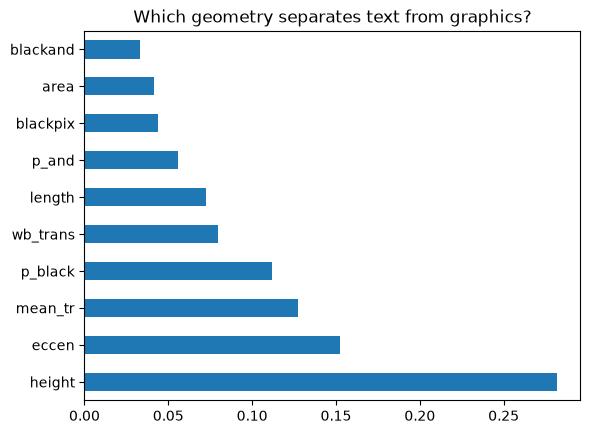

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='Which geometry separates text from graphics?')